# DSP Lab 5: Emotion Classification Using Machine Learning

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import numpy as np
import seaborn as sns
import re

plt.rcdefaults()

In [2]:
import PIL
print(PIL.__version__)

13.0.0


In [3]:
import sys, pandas, spacy, sklearn, transformers, torch

print(sys.version)
print("pandas:", pandas.__version__)
print("spaCy:", spacy.__version__)
print("scikit-learn:", sklearn.__version__)
print("transformers:", transformers.__version__)
print("torch:", torch.__version__)

C:\Users\eveli\anaconda3\envs\nlp_vu2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


3.12.16 | packaged by Anaconda, Inc. | (main, Oct 26 2026, 20:13:05) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.6
spaCy: 3.7.2
scikit-learn: 1.9.1
transformers: 5.24.1
torch: 2.15.0+cpu


## 1. Text dataset preparation

Use the metadata.csv file from the Lithuanian Emotional Speech Corpus (EMO) to create a text classification dataset.

In [4]:
metadata = pd.read_csv("metadata.csv", header=None, names=["{audio_path}|{speaker_id}|{text}"])
metadata.head()

,{audio_path}|{speaker_id}|{text}
0,wavs/D/F2/0701-F2D/0701-F2D-0001.wav|07|džiugi...
1,wavs/D/F2/0701-F2D/0701-F2D-0002.wav|07|sėkmė ...
2,wavs/D/F2/0701-F2D/0701-F2D-0003.wav|07|čekijo...
3,wavs/D/F2/0701-F2D/0701-F2D-0004.wav|07|festiv...
4,wavs/D/F2/0701-F2D/0701-F2D-0005.wav|07|didžiu...


In [5]:
metadata.shape  # rows, columns

(349696, 1)

In [6]:
metadata = pd.read_csv(
    "metadata.csv",
    sep="|",
    header=None,
    names=["audio_path", "speaker_id", "text"],
    dtype=str,
    encoding="utf-8",
)
metadata.head()

,audio_path,speaker_id,text
0,wavs/D/F2/0701-F2D/0701-F2D-0001.wav,07,džiugios naujienos iš čekijos
1,wavs/D/F2/0701-F2D/0701-F2D-0002.wav,07,sėkmė lydėjo mūsų mokyklos mokinį vilių
2,wavs/D/F2/0701-F2D/0701-F2D-0003.wav,07,čekijos sostinėje prahoje vykusiame tarptautin...
3,wavs/D/F2/0701-F2D/0701-F2D-0004.wav,07,festivalyje laimėta pirmoji vieta
4,wavs/D/F2/0701-F2D/0701-F2D-0005.wav,07,didžiuojamės ir džiaugiamės įspūdingu pasiekim...


- Extract the text samples and their corresponding emotion labels.

In [7]:
parts = metadata["audio_path"].str.split("/")
metadata["emotion"] = parts.str[1]

# 1. Extract text samples and their emotion labels
dataset = metadata[["text", "emotion"]].copy()
dataset.head()

,text,emotion
0,džiugios naujienos iš čekijos,D
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D
2,čekijos sostinėje prahoje vykusiame tarptautin...,D
3,festivalyje laimėta pirmoji vieta,D
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D


In [8]:
dataset.shape

(349696, 2)

In [9]:
dataset["emotion"].value_counts()

emotion
P    72463
L    71401
D    69642
N    68103
Z    68087
Name: count, dtype: int64

## Normalize text

In [10]:
# Check for missing values and empty/whitespace-only strings
for column in ["text", "emotion"]:
    empty = dataset[column].isna() | dataset[column].astype(str).str.strip().eq("")
    print(f"{column}: {empty.sum()} empty values")

text: 0 empty values
emotion: 0 empty values


In [11]:
dataset["text_norm"] = (
    metadata["text"]
    .str.normalize("NFC")
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.lower()
)
dataset.head()

,text,emotion,text_norm
0,džiugios naujienos iš čekijos,D,džiugios naujienos iš čekijos
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D,sėkmė lydėjo mūsų mokyklos mokinį vilių
2,čekijos sostinėje prahoje vykusiame tarptautin...,D,čekijos sostinėje prahoje vykusiame tarptautin...
3,festivalyje laimėta pirmoji vieta,D,festivalyje laimėta pirmoji vieta
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D,didžiuojamės ir džiaugiamės įspūdingu pasiekim...


- Identify and exclude all texts associated with multiple emotion labels.

In [12]:
n_emotions = dataset.groupby("text_norm")["emotion"].nunique()
multi_texts = n_emotions[n_emotions > 1].index

print("Total rows:", len(dataset))
print("Unique texts:", len(n_emotions))
print("Unique texts with multiple emotions:", len(multi_texts))
print("Rows with multiple emotions:", dataset["text_norm"].isin(multi_texts).sum(), "of", len(dataset))


Total rows: 349696
Unique texts: 135214
Unique texts with multiple emotions: 263
Rows with multiple emotions: 3548 of 349696


In [13]:
multi_emotion_examples = (
    dataset[dataset["text_norm"].isin(multi_texts)]
    .groupby("text_norm", as_index=False)
    .agg(
        text=("text", "first"),
        emotion_labels=("emotion", lambda labels: sorted(labels.dropna().unique())),
    )
)

print(multi_emotion_examples[["text", "emotion_labels"]].head(10).to_string(index=False))

                                                                       text emotion_labels
                                                         adelinos medžioklė         [D, L]
                                                              akivaizdu kad         [L, Z]
          akyse sutavaruoja suima neapsakomas pasibjaurėjimas viskuo aplink         [L, P]
                                                            akyse tavaruoja         [L, P]
                                                            antroje vietoje         [N, Z]
                                                           apie ką tu kalbi         [N, P]
                                                                    ar gali         [N, P]
                                                                ar girdėjai         [N, P]
ar man teisingai atrodo kad kuo toliau tuo labiau tavo smegenys susitraukia         [N, P]
    ar man teisingai atrodo kad tu kiekvienais metais daraisi vis bjauresnė         [N, P]

In [14]:
# 2. Exclude texts with multiple emotion labels
dataset2 = dataset[~dataset["text_norm"].isin(multi_texts)]

In [15]:
dataset2.shape

(346148, 3)

In [16]:
dataset2["emotion"].value_counts()

emotion
P    71978
L    70830
D    69174
Z    67988
N    66178
Name: count, dtype: int64

- Remove duplicate texts, ensuring that each unique text appears only once in the dataset.

In [17]:
total_rows = len(dataset2)
unique_texts = dataset2["text_norm"].nunique()
duplicate_rows = dataset2["text_norm"].duplicated().sum()

print("Total rows:", total_rows)
print("Unique texts:", unique_texts)
print("Duplicate rows:", duplicate_rows)

Total rows: 346148
Unique texts: 134951
Duplicate rows: 211197


In [18]:
duplicates = dataset2.groupby(["text_norm", "emotion"]).size().reset_index(name="occurrences")
duplicates = duplicates.sort_values("occurrences", ascending=False)

duplicates.head(10)

,text_norm,emotion,occurrences
21479,eik tu sau,N,745
117904,tu įsivaizduoji,N,722
2911,ar gali patikėti,N,399
51797,kas galėjo pagalvoti,N,317
129630,įsivaizduok sau,N,184
52296,kas per stebuklas,N,140
101627,su gimtadieniu,D,129
6692,atrodo nesąmonė,N,120
49747,kaip tai įmanoma,N,107
101623,su gimimo diena,D,102


In [19]:
# 3. remove duplicate texts
dataset3 = dataset2.drop_duplicates(subset="text_norm", keep="first").reset_index(drop=True)

In [20]:
assert dataset3["text_norm"].is_unique

In [21]:
dataset3.shape

(134951, 3)

In [22]:
dataset3["emotion"].value_counts()

emotion
Z    30982
P    28057
L    26687
D    24997
N    24228
Name: count, dtype: int64

In [23]:
datasets = {
    "1_raw": dataset,
    "2_no_multi_emotion": dataset2,
    "3_no_duplicates": dataset3,
}

def summarize(d):
    words = d["text"].str.split().str.len()
    chars = d["text"].str.len()
    return {
        "rows": len(d),
        "unique_texts": d["text"].nunique(),
        "total_words": words.sum(),
        "avg_words": round(words.mean(), 2),
        "avg_chars": round(chars.mean(), 2),
    }

summary = pd.DataFrame({name: summarize(d) for name, d in datasets.items()}).T

# change compared with the previous stage
summary["rows_change"] = summary["rows"].diff()
summary["rows_change_%"] = (summary["rows"].pct_change() * 100).round(2)

summary[["rows", "unique_texts", "total_words"]] = (
    summary[["rows", "unique_texts", "total_words"]].astype("int64")
)

summary

,rows,unique_texts,total_words,avg_words,avg_chars,rows_change,rows_change_%
1_raw,349696,135214,2288125,6.54,43.40,NaN,NaN
2_no_multi_emotion,346148,134951,2278261,6.58,43.68,-3548.0,-1.01
3_no_duplicates,134951,134951,978027,7.25,48.61,-211197.0,-61.01


- Save the resulting dataset in CSV format, containing the text samples and their emotion labels, for
further analysis and classification.

In [24]:
dataset_final = dataset3[["text_norm", "emotion"]].copy()
dataset_final.columns = ["text", "label"]

# Save the cleaned dataset
dataset_final.to_csv("emo_text_dataset.csv", index=False)

dataset_final.head()

,text,label
0,džiugios naujienos iš čekijos,D
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D
2,čekijos sostinėje prahoje vykusiame tarptautin...,D
3,festivalyje laimėta pirmoji vieta,D
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D


## Primary text analysis

In [25]:
df = pd.read_csv("emo_text_dataset.csv")
df

,text,label
0,džiugios naujienos iš čekijos,D
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D
2,čekijos sostinėje prahoje vykusiame tarptautin...,D
3,festivalyje laimėta pirmoji vieta,D
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D
...,...,...
134946,stebimas kūrinys kaip jis,Z
134947,verčia pasijusti,Z
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z


In [26]:
print(df["text"].describe())
print("")
print(df["label"].describe())

df['label'].unique()

count                            134951
unique                           134951
top       džiugios naujienos iš čekijos
freq                                  1
Name: text, dtype: object

count     134951
unique         5
top            Z
freq       30982
Name: label, dtype: object


<StringArray>
['D', 'L', 'N', 'P', 'Z']
Length: 5, dtype: str

In [27]:
from IPython.display import display, Markdown
def display_basic_info(data):
    data = pd.DataFrame(data)
    
    display(Markdown("### Head of the dataset:"))
    display(data.head())
        
    display(Markdown("### Tail of the dataset:"))
    display(data.tail())

    display(Markdown("### Summary statistics:"))
    display(data.describe())

    display(Markdown("### Info about the dataset:"))
    display(data.info())
    
    display(Markdown("### Dimensions of the dataset:"))
    display(data.shape)
    
    display(Markdown("### Columns of the dataset:"))
    display(data.columns)
    
    display(Markdown("### Unique Values count:"))
    display(data.nunique())
display_basic_info(df)

# https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.describe.html

### Head of the dataset:

,text,label
0,džiugios naujienos iš čekijos,D
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D
2,čekijos sostinėje prahoje vykusiame tarptautin...,D
3,festivalyje laimėta pirmoji vieta,D
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D


### Tail of the dataset:

,text,label
134946,stebimas kūrinys kaip jis,Z
134947,verčia pasijusti,Z
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z
134950,sau suteikimas,Z


### Summary statistics:

,text,label
count,134951,134951
unique,134951,5
top,džiugios naujienos iš čekijos,Z
freq,1,30982


... (5 outputs left out)

### Columns of the dataset:

Index(['text', 'label'], dtype='str')

### Unique Values count:

text     134951
label         5
dtype: int64

In [28]:
counts = df['label'].value_counts()

percs = df['label'].value_counts(normalize=True).mul(100).round(2).astype(str) + ' %'

pd.concat([counts,percs], axis=1, keys=['count', 'percentage'])

,count,percentage
label,,
Z,30982,22.96 %
P,28057,20.79 %
L,26687,19.78 %
D,24997,18.52 %
N,24228,17.95 %


In [29]:
df.isnull().sum()

text     0
label    0
dtype: int64

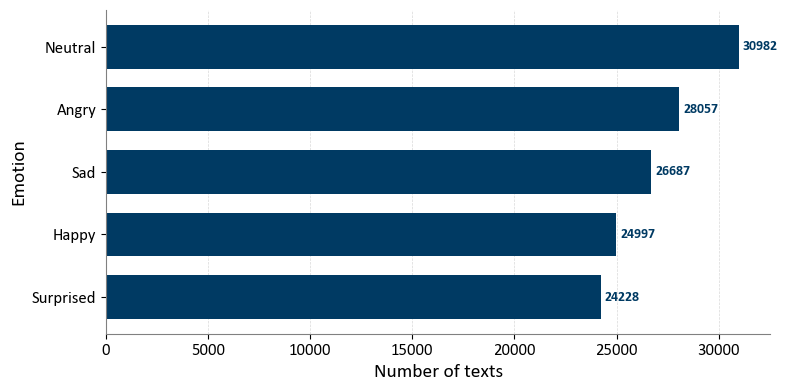

In [31]:
import matplotlib
import matplotlib.pyplot as plt

plt.close()

matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = ['Calibri', 'DejaVu Sans']

code2emotion = {
    "N": "Surprised",
    "P": "Angry",
    "D": "Happy",
    "L": "Sad",
    "Z": "Neutral",  
}

def make_bar(ax=None):                                           
    standalone = ax is None                                     
    if standalone:                                                
        fig, ax = plt.subplots(figsize=(8, 4))                  

    # Count texts per emotion code, smallest at the bottom
    label_counts = df["label"].value_counts().sort_values(ascending=True)

    x = label_counts.values
    y = [code2emotion.get(c, c) for c in label_counts.index]  

    bars = ax.barh(y, x, color="#003A63", height=0.7)

    ax.set_xlabel("Number of texts", fontsize=14)
    ax.set_ylabel("Emotion", fontsize=14)

    ax.set_axisbelow(True)
    ax.grid(axis="x", color="gray", linestyle="--", linewidth=0.5, alpha=0.3)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("gray")
    ax.spines["bottom"].set_color("gray")

    ax.bar_label(bars, color="#003A63", fontsize=10,
                 label_type="edge", fontweight="bold", padding=3)

    if standalone:                                               
        plt.tight_layout()
        plt.show()

make_bar()

plt.rcParams.update({
    "axes.labelsize": 16,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


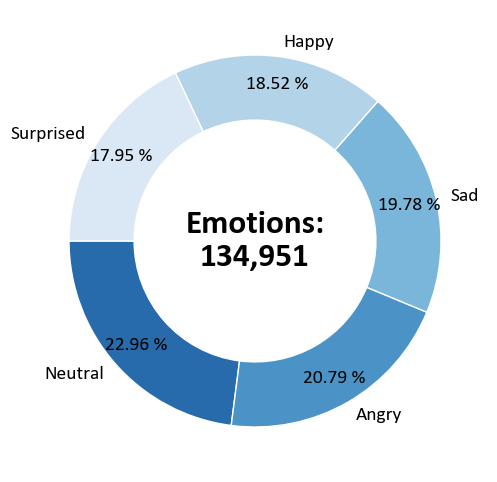

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns


def make_pie(sizes, text, labels, palette, alpha, ax=None):
    standalone = ax is None
    if standalone:
        fig, ax = plt.subplots(figsize=(6, 6))
    ax.axis('equal')

    colors_with_alpha = [(*color, alpha) for color in palette]

    def my_autopct(pct):
        return '{:.2f} %'.format(pct)

    kwargs = dict(colors=colors_with_alpha, startangle=180, autopct=my_autopct,
                  textprops={'color': 'black', 'fontsize': 14})          
    outside, _, _ = ax.pie(sizes, radius=1, pctdistance=0.85,
                           labels=labels, labeldistance=1.08, **kwargs)  

    width = 0.35
    plt.setp(outside, width=width, edgecolor='white')

    ax.text(0, 0, text, ha='center', size=24, fontweight='bold', va='center')  
    if standalone:
        plt.show()

data = df
col = "label"
counts = data[col].value_counts()

sizes = counts.values
labels = [code2emotion.get(c, c) for c in counts.index]
text = "Emotions:\n{:,}".format(len(data))                # total number of texts

palette = sns.color_palette("Blues_r", len(labels))
alpha = 0.9

make_pie(sizes, text, labels, palette, alpha)

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


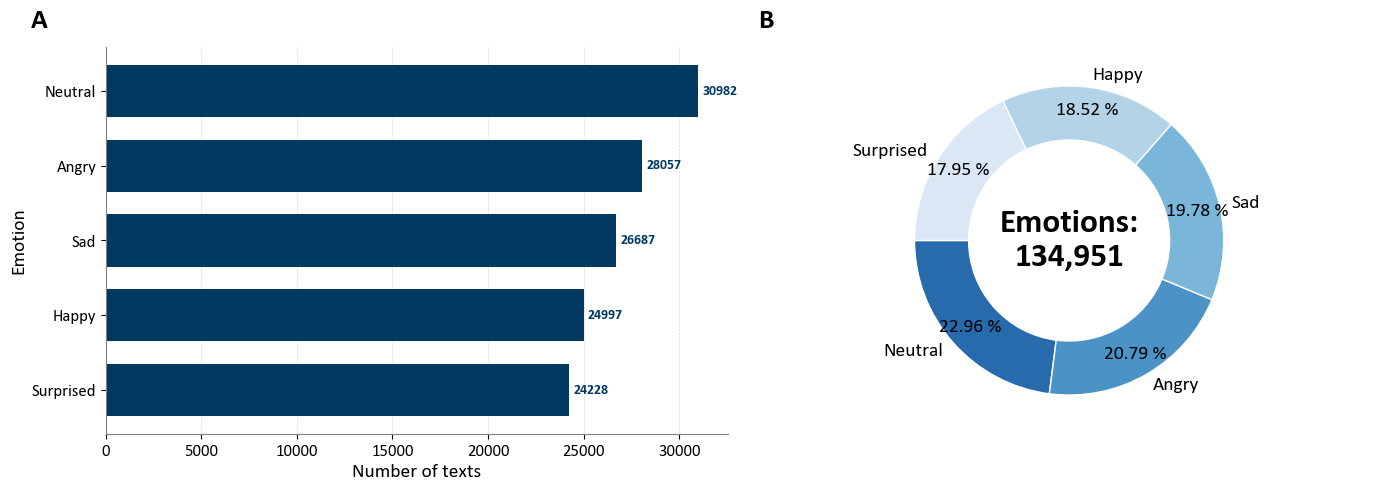

In [33]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

make_bar(ax1)
make_pie(sizes, text, labels, palette, alpha, ax=ax2)

ax1.text(-0.12, 1.05, "A", transform=ax1.transAxes, fontsize=20, fontweight="bold")
ax2.text(0.0, 1.05, "B", transform=ax2.transAxes, fontsize=20, fontweight="bold")

plt.tight_layout()
plt.savefig("emotion_distribution.pdf", bbox_inches="tight")  
plt.show()

## 2. Text analysis

In [ ]:
import spacy
nlp = spacy.load("lt_core_news_lg")

In [ ]:
import spacy
nlp = spacy.blank("lt")      # tokenizer only, no tagger or parser

df['symbols_length'] = df["text"].apply(len)
df['word_count'] = df["text"].apply(lambda x: len(x.split())) # Žodžių skaičius
df['rounded_average_word_length'] = df['text'].apply(lambda x: round(sum(len(word) for word in x.split()) / len(x.split())) if len(x.split()) > 0 else 0)
df['average_word_length'] = df['text'].apply(lambda x: (sum(len(word) for word in x.split()) / len(x.split())) if len(x.split()) > 0 else 0)

stop_lists = []
for doc in nlp.pipe(df["text"], batch_size=1000):
    stop_lists.append([t.text for t in doc if t.is_stop])

df["stop_words"] = stop_lists
df["stop_words_count"] = df["stop_words"].str.len()

In [8]:
df.head()

,text,label,n_words,symbols_length,word_count,rounded_average_word_length,average_word_length,stop_words,stop_words_count
0,džiugios naujienos iš čekijos,D,4,29,4,6,6.500000,[iš],1
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D,6,39,6,6,5.666667,[mūsų],1
2,čekijos sostinėje prahoje vykusiame tarptautin...,D,8,76,8,9,8.625000,[],0
3,festivalyje laimėta pirmoji vieta,D,4,33,4,8,7.500000,[],0
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D,11,83,11,7,6.636364,"[ir, bei, ir, jo]",4


In [ ]:
from spacy.lang.lt.stop_words import STOP_WORDS   # Lithuanian stop words used by spaCy

words = df["text"].str.split()

df["symbols_length"] = df["text"].str.len()
df["word_count"] = words.str.len()

total_chars = words.apply(lambda w: sum(len(x) for x in w))
df["average_word_length"] = (total_chars / df["word_count"]).where(df["word_count"] > 0, 0)
df["rounded_average_word_length"] = df["average_word_length"].round().astype(int)

# stop words: simple set lookup, no spaCy pipeline
df["stop_words"] = words.apply(lambda w: [x for x in w if x.lower() in STOP_WORDS])
df["stop_words_count"] = df["stop_words"].str.len()
df.head()

In [ ]:
df.tail()

,text,label,stop_words,stop_words_count,symbols_length,word_count,rounded_average_word_length,average_word_length
134946,stebimas kūrinys kaip jis,Z,"[kaip, jis]",2,25,4,6,5.500000
134947,verčia pasijusti,Z,[],0,16,2,8,7.500000
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z,"[į, bet, jeigu, vien, tik]",5,56,10,5,4.700000
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z,"[mano, ar]",2,63,9,6,6.111111
134950,sau suteikimas,Z,[sau],1,14,2,6,6.500000


In [ ]:
print("\nOverall word count: {}".format(df["word_count"].sum()))
print("Overall symbol count: {}".format(df["symbols_length"].sum()))
print("Average word length: {}".format(df["average_word_length"].mean()))
print("Count of stop words: {}".format(df["stop_words_count"].sum()))

df[["symbols_length", "word_count", "average_word_length", "stop_words_count"]].describe().T.drop("count",axis=1)


Overall word count: 978027
Overall symbol count: 6559688
Average word length: 5.94294890229434
Count of stop words: 319002


,mean,std,min,25%,50%,75%,max
symbols_length,48.607924,28.368765,3.0,26.0,42.000000,67.000000,162.0
word_count,7.247275,4.117281,2.0,4.0,6.000000,10.000000,28.0
average_word_length,5.942949,1.359654,1.0,5.0,5.823529,6.727273,15.5
stop_words_count,2.363836,1.985071,0.0,1.0,2.000000,3.000000,18.0


- Text length: Visualize and compare the distributions of text lengths (in words) across the emotion 
classes.

In [11]:
df["n_words"] = df["text"].str.split().str.len()

# Same order in every chart: by number of texts, largest first
order = df["label"].value_counts().index.tolist()

summary = df.groupby("label")["n_words"].agg(
    total_words="sum",
    average_words="mean",
    text_count="count",
).round(2).sort_values("total_words", ascending=False)

summary

,total_words,average_words,text_count
label,,,
Z,239795,7.74,30982
P,207111,7.38,28057
L,182165,6.83,26687
D,178380,7.14,24997
N,170576,7.04,24228


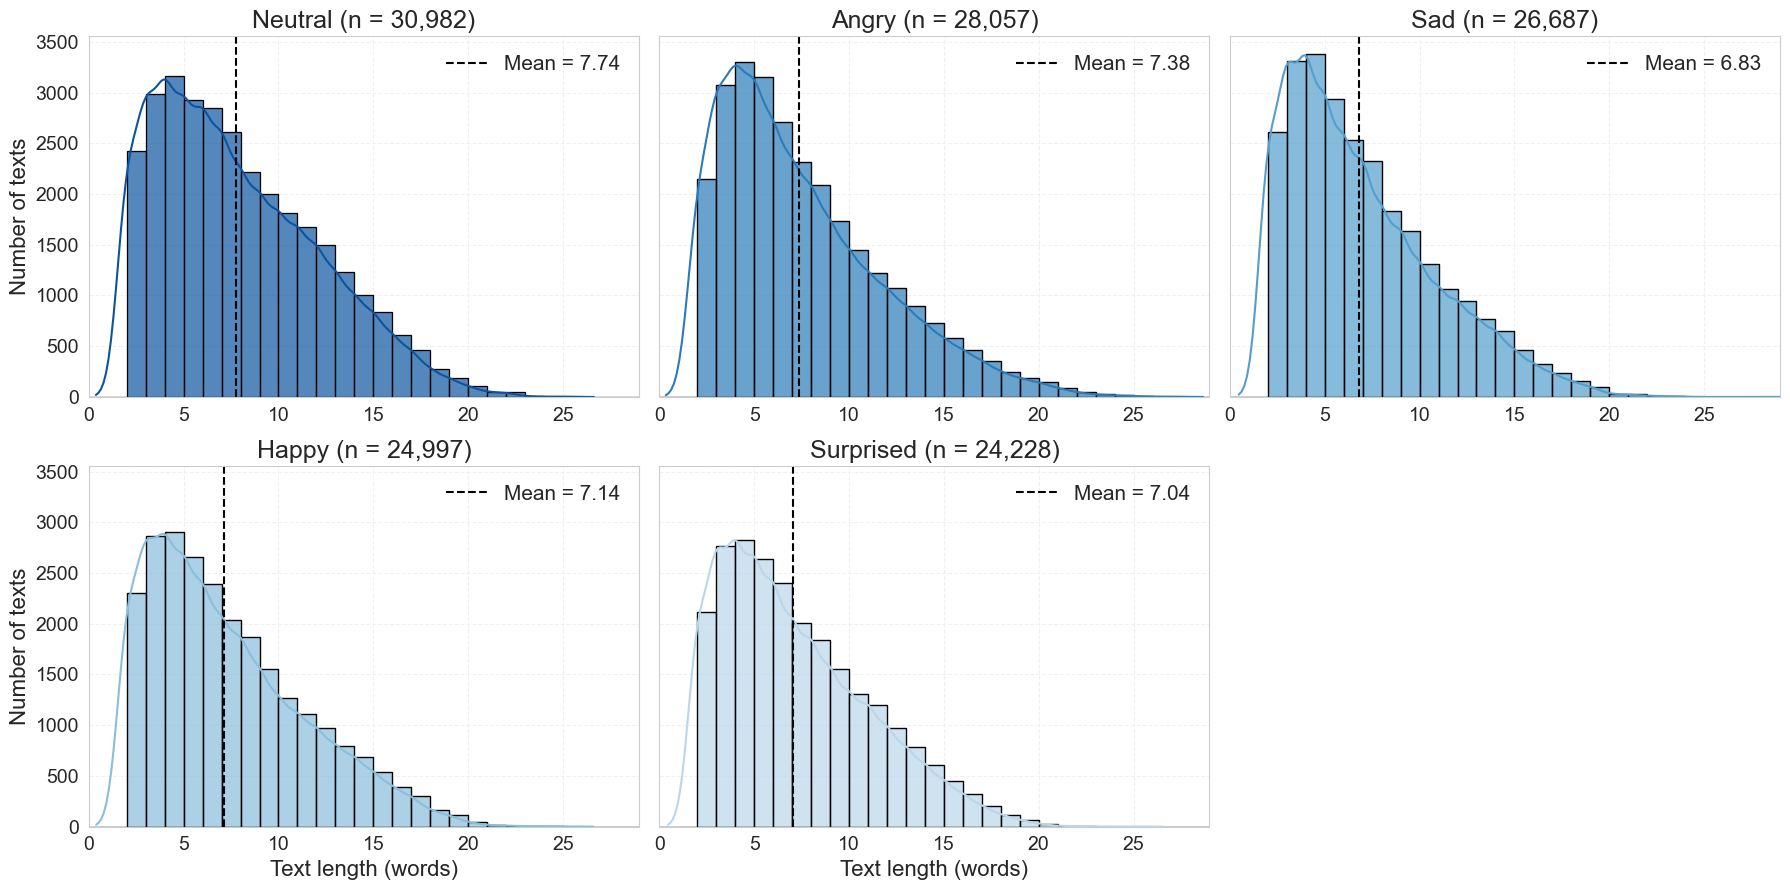

In [12]:
code2emotion = {
    "N": "Surprised",
    "P": "Angry",
    "D": "Happy",
    "L": "Sad",
    "Z": "Neutral",
}

sns.set_style('whitegrid')

order = df["label"].value_counts().index.tolist()
colors = sns.color_palette("Blues_r", len(order) + 1)[:len(order)]

max_words = int(df["n_words"].max())
bins = np.arange(0, max_words + 2, 1)

n_cols = 3
n_rows = math.ceil(len(order) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows),
                         sharex=True, sharey=True)
axes = axes.flatten()

for ax, name, color in zip(axes, order, colors):
    subset = df.loc[df["label"] == name, "n_words"]
    mean_val = subset.mean()

    sns.histplot(subset, bins=bins, kde=True,
                 kde_kws={"cut": 3, "clip": (0, None)},
                 color=color, edgecolor="black", alpha=0.7, ax=ax)

    ax.axvline(mean_val, color="black", linestyle="--", linewidth=1.5,
               label=f"Mean = {mean_val:.2f}")
    ax.legend(frameon=False, fontsize=15)

    emotion = code2emotion.get(name, name)
    ax.set_title(f"{emotion} (n = {len(subset):,})", fontsize=18)
    ax.set_xlabel("Text length (words)", fontsize=16)
    ax.set_ylabel("Number of texts", fontsize=16)
    ax.grid(True, color="#f0f0f0", axis="both", linestyle="--")
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=14)
    ax.tick_params(labelbottom=True)                 
    ax.set_xlim(0, max_words + 1)

for ax in axes[len(order):]:
    ax.axis("off")

fig.tight_layout()
fig.savefig("word_length_histograms.pdf", bbox_inches="tight")
plt.show()

- Vocabulary analysis: Apply lemmatization and stop-word removal.

Stop-words

In [ ]:
from spacy.lang.lt.stop_words import STOP_WORDS

stopwords = nlp.Defaults.stop_words
stopwords = set(stopwords)
print(stopwords == STOP_WORDS)
print(len(stopwords))

True
1314


In [3]:
import spacy
nlp = spacy.load("lt_core_news_lg", disable=["parser", "ner"])

C:\Users\eveli\anaconda3\envs\nlp_vu2\Lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'lt_core_news_lg' (3.8.0) was trained with spaCy v3.8.0 and may not be 100% compatible with the current version (3.7.2). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [9]:
import re

stopwords = set(nlp.Defaults.stop_words) 

extra_stopwords = [
    # auxiliary and modal verbs
    "yra", "buvo", "būti", "gali", "galėjo", "galima", "turi", "nėra", "būtų", "bus", "esu", "esi",
    # pronouns and adverbs
    "čia", "ten", "ką", "ko", "dabar", "visi", "viską", "todėl",
    # quantifiers
    "daug", "daugiau", "tiek",
]
stopwords.update(extra_stopwords)


url_re   = re.compile(r'(http|https)?://\S+|www\.\S+')
punct_re = re.compile(r'[^\w\s]')
digit_re = re.compile(r'\d+')

def text_for_common_words(text):
    text = url_re.sub('', text)
    text = punct_re.sub(' ', text)
    text = digit_re.sub('', text)
    words = [w for w in text.split()
             if len(w) > 1 and w.lower() not in stopwords]
    return ' '.join(words)

df['for_common_words'] = df['text'].apply(text_for_common_words)
df.tail()

,text,label,for_common_words,preprocess_text
134946,stebimas kūrinys kaip jis,Z,stebimas kūrinys,stebimas kūrinys
134947,verčia pasijusti,Z,verčia pasijusti,versti pasijusti
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z,nugula aprašymą kūrinys galėtų,nugula aprašymas kūrinys galėti
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z,svarbiausia nuomone žiūrint šokio judesio spek...,svarbiausia nuomonė žiūrint šokis judesys spek...
134950,sau suteikimas,Z,suteikimas,suteikimas


In [15]:
df.head()

,text,label,for_common_words
0,džiugios naujienos iš čekijos,D,džiugios naujienos čekijos
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D,sėkmė lydėjo mokyklos mokinį vilių
2,čekijos sostinėje prahoje vykusiame tarptautin...,D,čekijos sostinėje prahoje vykusiame tarptautin...
3,festivalyje laimėta pirmoji vieta,D,festivalyje laimėta pirmoji vieta
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D,didžiuojamės džiaugiamės įspūdingu pasiekimu s...


- Vocabulary analysis: Identify and compare the most frequent words in each emotion class. Generate a word cloud for each emotion class to visualize its most frequent words.

### Most frequent words in text

In [ ]:
from collections import Counter

all_words = " ".join(df['for_common_words']).split()
print(Counter(all_words).most_common(20))

for label, group in df.groupby('label'):
    words = " ".join(group['for_common_words']).split()
    print(label, Counter(words).most_common(10))

[('labai', 2598), ('nieko', 1436), ('žmonės', 1432), ('metų', 1334), ('tikrai', 1102), ('šiandien', 1089), ('reikia', 1058), ('dieną', 1056), ('gyvenimo', 1007), ('žmonių', 1003), ('miesto', 985), ('viskas', 962), ('atrodo', 946), ('žmogus', 938), ('visada', 927), ('tada', 859), ('niekada', 855), ('visą', 844), ('džiaugsmas', 824), ('metu', 820)]
D [('labai', 1067), ('džiaugsmas', 758), ('džiaugsmo', 590), ('dėkoju', 456), ('dieną', 440), ('laimės', 421), ('džiaugiuosi', 387), ('diena', 386), ('gyvenimo', 361), ('šiandien', 357)]
L [('labai', 638), ('nieko', 437), ('liūdna', 427), ('niekas', 392), ('žmogus', 336), ('liūdesys', 335), ('žmonės', 321), ('atrodo', 311), ('tada', 276), ('kartais', 272)]
N [('neįtikėtina', 725), ('patikėti', 599), ('eik', 414), ('žmonės', 387), ('metų', 370), ('žinojai', 348), ('įsivaizduoji', 340), ('pagalvoti', 322), ('nepatikėsi', 290), ('žemės', 285)]
P [('nieko', 527), ('nori', 373), ('nekenčiu', 370), ('reikia', 360), ('eik', 295), ('nu', 279), ('žmonė

In [ ]:
from collections import Counter

temp_list = df["for_common_words"].dropna().str.lower().apply(lambda x: str(x).split())
top = Counter([item for sublist in temp_list for item in sublist])
temp = pd.DataFrame(top.most_common(20))
temp.columns = ['Common_words','count']
temp.style.background_gradient(cmap='Blues')

,Common_words,count
0,labai,2598
1,nieko,1436
2,žmonės,1432
3,metų,1334
4,tikrai,1102
5,šiandien,1089
6,reikia,1058
7,dieną,1056
8,gyvenimo,1007
9,žmonių,1003


In [8]:
top = {}
for label, group in df.groupby('label'):
    words = " ".join(group['for_common_words']).split()
    top[label] = [f"{w} ({c})" for w, c in Counter(words).most_common(10)]

common_emotion = pd.DataFrame(top, index=range(1, 11))
common_emotion.index.name = 'No.'
common_emotion

,D,L,N,P,Z
No.,,,,,
1,labai (1067),labai (638),neįtikėtina (725),nieko (527),miesto (652)
2,džiaugsmas (758),nieko (437),patikėti (599),nori (373),labai (525)
3,džiaugsmo (590),liūdna (427),eik (414),nekenčiu (370),vilniaus (479)
4,dėkoju (456),niekas (392),žmonės (387),reikia (360),sako (418)
5,dieną (440),žmogus (336),metų (370),eik (295),metu (395)
6,laimės (421),liūdesys (335),žinojai (348),nu (279),žmonių (382)
7,džiaugiuosi (387),žmonės (321),įsivaizduoji (340),žmonės (266),lietuvos (376)
8,diena (386),atrodo (311),pagalvoti (322),tikrai (257),pavyzdžiui (374)
9,gyvenimo (361),tada (276),nepatikėsi (290),niekada (251),šiandien (368)


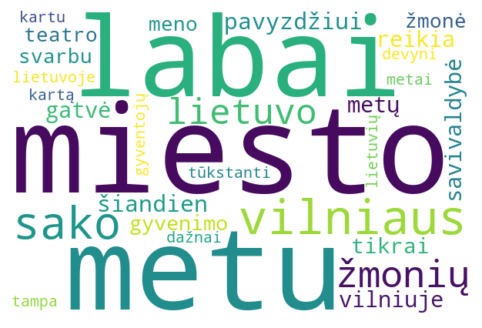

In [17]:
from wordcloud import WordCloud
from PIL import Image

text = " ".join(df.loc[df['label'] == 'Z', 'for_common_words'])

wc = WordCloud(background_color='white', max_words=30,
               width=600, height=400, collocations=False).generate(text)

plt.figure(figsize=(6, 4))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()


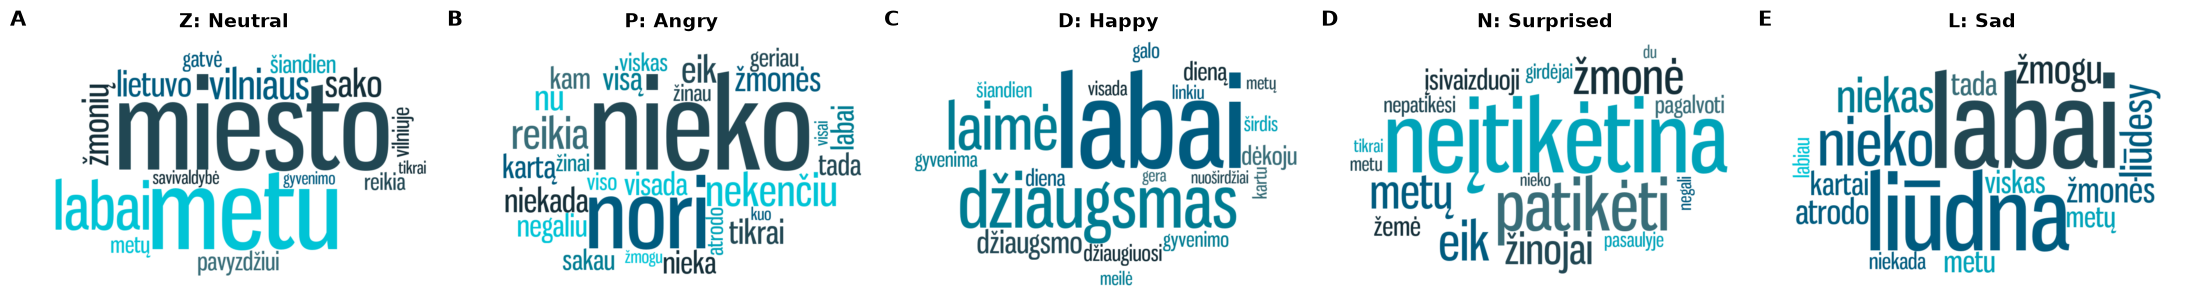

In [19]:
import string
import os
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from PIL import Image

mask = np.array(Image.open('cloud_figure - Copy (2).png'))
font_path = os.path.join('Gnuolane Rg.otf')

def color_palette(word, font_size, position, orientation, random_state=None, **kwargs):
    colors = ["#005B7F", "#007C92", "#00A3B9", "#00C4D6", "#386D78", "#214753", "#142E38"]
    return np.random.choice(colors)

# short code in the data -> full title for the figure
titles = {
    'Z': 'Z: Neutral',
    'P': 'P: Angry',
    'D': 'D: Happy',
    'N': 'N: Surprised',
    'L': 'L: Sad',
}

fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for i, (ax, (code, title)) in enumerate(zip(axes, titles.items())):
    text = " ".join(df.loc[df['label'] == code, 'for_common_words'])

    wordcloud = WordCloud(
        background_color='white',
        max_words=30,
        mask=mask,
        contour_width=0,
        relative_scaling=0.8,
        height=600,
        font_path=font_path,
        min_font_size=40,
        max_font_size=300,
        random_state=42,
        prefer_horizontal=0.9,
        color_func=color_palette,
        collocations=False,
        stopwords=nlp.Defaults.stop_words
    ).generate(text)

    ax.imshow(wordcloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.text(-0.05, 1.1, string.ascii_uppercase[i], transform=ax.transAxes,
            fontsize=15, fontweight='bold', va='top')
s
plt.tight_layout()
plt.savefig('worclouds.png', dpi=600, bbox_inches='tight')
plt.show()

In [20]:
import re

url_re    = re.compile(r'(http|https)?://\S+|www\.\S+')
punct_re  = re.compile(r'[^\w\s]')
digit_re  = re.compile(r'\d+')

extra_stopwords = [
    # auxiliary and modal verbs
    "yra", "buvo", "būti", "gali", "galėjo", "galima", "turi", "nėra", "būtų", "bus", "esu", "esi",
    # pronouns and adverbs
    "čia", "ten", "ką", "ko", "dabar", "visi", "viską", "todėl",
    # quantifiers
    "daug", "daugiau", "tiek",
]
stopwords.update(extra_stopwords)

def clean_text(text):
    text = url_re.sub('', text)
    text = punct_re.sub(' ', text)
    text = digit_re.sub('', text)
    return ' '.join(w for w in text.split() if len(w) > 1)

cleaned = df['text'].apply(clean_text)

print(nlp.pipe_names)
docs = nlp.pipe(cleaned, batch_size=256, disable=["parser", "ner", "senter"])

# 3. lemmas + stopword filtering
df['preprocess_text'] = [
    ' '.join(l for l in (t.lemma_.lower() for t in doc) if l not in stopwords)
    for doc in docs
]
df.tail()

['tok2vec', 'morphologizer', 'tagger', 'lemmatizer', 'attribute_ruler']


,text,label,for_common_words,preprocess_text
134946,stebimas kūrinys kaip jis,Z,stebimas kūrinys,stebimas kūrinys
134947,verčia pasijusti,Z,verčia pasijusti,versti pasijusti
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z,nugula aprašymą kūrinys galėtų,nugula aprašymas kūrinys galėti
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z,svarbiausia nuomone žiūrint šokio judesio spek...,svarbiausia nuomonė žiūrint šokis judesys spek...
134950,sau suteikimas,Z,suteikimas,suteikimas


In [ ]:
# save preprocessed text
df.to_csv("dataset_preprocessed.csv", index=False, encoding="utf-8-sig")

In [2]:
df = pd.read_csv("dataset_preprocessed.csv")
df['preprocess_text'] = df['preprocess_text'].fillna("")
df

,text,label,for_common_words,preprocess_text
0,džiugios naujienos iš čekijos,D,džiugios naujienos čekijos,džiugus naujiena čekija
1,sėkmė lydėjo mūsų mokyklos mokinį vilių,D,sėkmė lydėjo mokyklos mokinį vilių,sėkmė lydėti mokykla mokinis vilus
2,čekijos sostinėje prahoje vykusiame tarptautin...,D,čekijos sostinėje prahoje vykusiame tarptautin...,čekija sostinė praha vykusiame tarptautinis ja...
3,festivalyje laimėta pirmoji vieta,D,festivalyje laimėta pirmoji vieta,festivalis laimėti pirmas vieta
4,didžiuojamės ir džiaugiamės įspūdingu pasiekim...,D,didžiuojamės džiaugiamės įspūdingu pasiekimu s...,didžiuojamės džiaugiamės įspūdingas pasiekimas...
...,...,...,...,...
134946,stebimas kūrinys kaip jis,Z,stebimas kūrinys,stebimas kūrinys
134947,verčia pasijusti,Z,verčia pasijusti,versti pasijusti
134948,nugula į aprašymą bet jeigu kūrinys galėtų būt...,Z,nugula aprašymą kūrinys galėtų,nugula aprašymas kūrinys galėti
134949,svarbiausia mano nuomone žiūrint šokio ar jude...,Z,svarbiausia nuomone žiūrint šokio judesio spek...,svarbiausia nuomonė žiūrint šokis judesys spek...


### POS analysis

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

names = {'Z': 'Neutral', 'P': 'Angry', 'D': 'Happy', 'N': 'Surprised', 'L': 'Sad'}
order = ['Z', 'P', 'D', 'N', 'L']

# 1. POS-tag every text once
texts = df['for_common_words'].fillna("").astype(str)
docs = nlp.pipe(texts, batch_size=256, disable=["parser", "ner", "lemmatizer"])
pos_per_text = [Counter(t.pos_ for t in doc) for doc in docs]

# 2. Counts per emotion class
pos_df = pd.DataFrame(pos_per_text).fillna(0).astype(int)
pos_df['label'] = df['label'].values
pos_counts = pos_df.groupby('label').sum().loc[order]
pos_counts.index = [names[l] for l in pos_counts.index]

# 3. Relative distribution (% of tokens in each class)
pos_pct = pos_counts.div(pos_counts.sum(axis=1), axis=0) * 100
pos_pct = pos_pct[pos_pct.mean().sort_values(ascending=False).index]
print(pos_pct.round(1))
pos_pct.round(2).to_csv("pos_distribution.csv")

# 4. Grouped bar chart
ax = pos_pct.T.plot(kind='bar', figsize=(12, 5), width=0.85)
ax.set_ylabel("Share of tokens, %")
ax.set_xlabel("POS tag")
ax.legend(title="Emotion")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("pos_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

           NOUN  VERB   ADJ  ADV  PRON  NUM  PROPN  DET    X  AUX  PART  \
Neutral    48.8  27.3  12.1  5.4   0.9  1.9    2.0  0.5  0.6  0.2   0.1   
Angry      37.4  39.3   9.2  7.1   2.3  1.0    0.8  1.0  0.6  0.4   0.3   
Happy      46.6  25.9  16.4  6.4   1.1  0.7    0.6  1.1  0.3  0.5   0.1   
Surprised  48.2  27.6  12.2  4.7   1.5  2.6    1.1  0.7  0.7  0.2   0.2   
Sad        41.2  33.9  11.8  7.6   2.0  0.9    0.4  0.8  0.4  0.5   0.3   

           CCONJ  PUNCT  ADP  SYM  INTJ  SPACE  SCONJ  
Neutral      0.1    0.1  0.0  0.0   0.0    0.0    0.0  
Angry        0.2    0.2  0.1  0.0   0.1    0.0    0.0  
Happy        0.1    0.0  0.1  0.0   0.0    0.0    0.0  
Surprised    0.1    0.1  0.0  0.0   0.0    0.0    0.0  
Sad          0.1    0.0  0.1  0.0   0.0    0.0    0.0  


## 3. Text Representation (Feature Extraction)

- Split the dataset into training and test sets using stratified sampling. 

In [5]:
from sklearn.model_selection import train_test_split

X = df['preprocess_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(len(X_train), len(X_test))
print('Training:', X_train.shape)
print('Testing:', X_test.shape)
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

107960 26991
Training: (107960,)
Testing: (26991,)
label
Z    0.230
P    0.208
L    0.198
D    0.185
N    0.180
Name: proportion, dtype: float64
label
Z    0.230
P    0.208
L    0.198
D    0.185
N    0.180
Name: proportion, dtype: float64


-  Frequency-based representations: Bag-of-Words (BoW), **TF-IDF**, or other method.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(
    ngram_range=(1, 1),   # unigrams; try (1, 2) to add bigrams
    min_df=2,             # ignore words found in fewer than 2 texts
    max_features=5000     # fixed vector length
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

print(X_train_tfidf.shape, X_test_tfidf.shape)

(107960, 5000) (26991, 5000)


- Static word embeddings: Word2Vec, GloVe, FastText, or another model.

In [40]:
import gensim
print(gensim.__version__)

4.4.0


In [5]:
import os
import time
import numpy as np
from gensim.models import Word2Vec
from gensim.models.word2vec import FAST_VERSION

print("FAST_VERSION:", FAST_VERSION)   # 0, 1 or 2 = fast; -1 = slow fallback

# 1. Train Word2Vec on the TRAINING texts only
start = time.time()
w2v = Word2Vec(
    [t.split() for t in X_train],
    vector_size=300,
    window=5,
    min_count=2,
    sg=1,                     # skip-gram
    seed=42,
    workers=os.cpu_count(),  
    epochs=5
)
print(f"Word2Vec trained in {time.time() - start:.1f} s")
wv = w2v.wv

# 2. Text -> average of word vectors
def text_to_vector(text):
    vecs = [wv[w] for w in text.split() if w in wv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size)

X_train_w2v = np.vstack([text_to_vector(t) for t in X_train])
X_test_w2v  = np.vstack([text_to_vector(t) for t in X_test])
print("Word2Vec:", X_train_w2v.shape, X_test_w2v.shape)


w2v.save("w2v.model")
np.save("X_train_w2v.npy", X_train_w2v)
np.save("X_test_w2v.npy", X_test_w2v)

FAST_VERSION: 1
Word2Vec trained in 13.8 s
Word2Vec: (107960, 300) (26991, 300)


- Contextual embeddings: BERT, Sentence-BERT, or other pretrained transformer model. 

In [7]:

import numpy as np
import torch
from sentence_transformers import SentenceTransformer

# Check device
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Original Lithuanian texts
train_texts = df.loc[X_train.index, "text"].fillna("").astype(str).tolist()
test_texts = df.loc[X_test.index, "text"].fillna("").astype(str).tolist()

# Smaller multilingual model
model = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

# Generate embeddings
X_train_sbert = model.encode(
    train_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

X_test_sbert = model.encode(
    test_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Train shape:", X_train_sbert.shape)
print("Test shape:", X_test_sbert.shape)


np.save("X_train_sbert.npy", X_train_sbert)
np.save("X_test_sbert.npy", X_test_sbert)


Using device: cpu


C:\Users\eveli\anaconda3\envs\nlp_vu2\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\eveli\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Batches: 100%|██████████| 844/844 [10:11<00:00,  1.38it/s]


Train shape: (107960, 384)
Test shape: (26991, 384)


## 4. Emotion Classification

Train a Logistic Regression classifier to predict the five emotion classes using each of the three selected 
text representations. 

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

lr = Pipeline([
    ('tfidf', TfidfVectorizer(min_df=2, max_features = 5000)),
    ('clf', LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42))
])

lr.fit(X_train, y_train)
predictions = lr.predict(X_test)
print(f'Logistic Regression accuracy: {metrics.accuracy_score(y_test, predictions):.3f}')

Logistic Regression accuracy: 0.838


TF-IDF
Accuracy: 0.716 | Precision (macro): 0.725 | Recall (macro): 0.712 | F1 (macro): 0.715

              precision    recall  f1-score   support

     Neutral      0.771     0.775     0.773      6197
       Angry      0.620     0.797     0.698      5612
       Happy      0.792     0.710     0.749      4999
   Surprised      0.758     0.647     0.698      4846
         Sad      0.685     0.633     0.658      5337

    accuracy                          0.716     26991
   macro avg      0.725     0.712     0.715     26991
weighted avg      0.724     0.716     0.717     26991



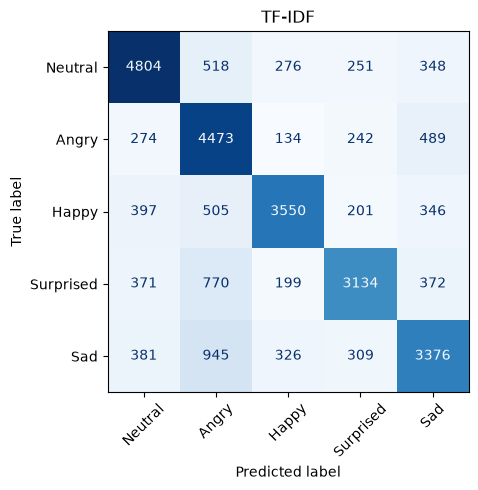

Word2Vec
Accuracy: 0.562 | Precision (macro): 0.569 | Recall (macro): 0.557 | F1 (macro): 0.557

              precision    recall  f1-score   support

     Neutral      0.614     0.662     0.637      6197
       Angry      0.479     0.658     0.554      5612
       Happy      0.667     0.583     0.622      4999
   Surprised      0.582     0.481     0.526      4846
         Sad      0.503     0.399     0.445      5337

    accuracy                          0.562     26991
   macro avg      0.569     0.557     0.557     26991
weighted avg      0.568     0.562     0.559     26991



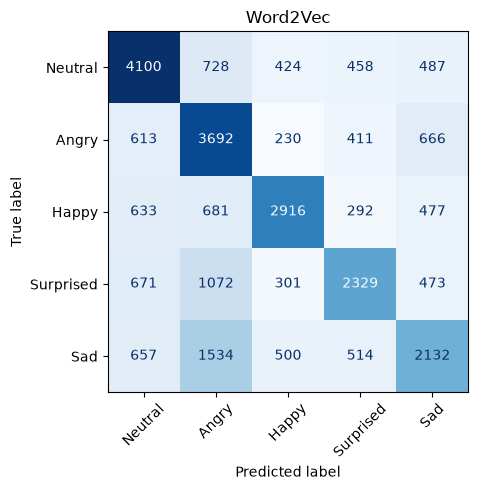

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

labels = ['Z', 'P', 'D', 'N', 'L']
names = {'Z': 'Neutral', 'P': 'Angry', 'D': 'Happy', 'N': 'Surprised', 'L': 'Sad'}
display_labels = [names[l] for l in labels]

def evaluate(model, X_test, y_test, title):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0)

    print(f"{title}")
    print(f"Accuracy: {acc:.3f} | Precision (macro): {p:.3f} | "
          f"Recall (macro): {r:.3f} | F1 (macro): {f1:.3f}\n")
    print(classification_report(y_test, y_pred, labels=labels,
                                target_names=display_labels, digits=3,
                                zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    return {'model': title, 'accuracy': acc, 'precision': p,
            'recall': r, 'f1': f1, 'cm': cm}

def plot_cm(cm, title, filename=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# TF-IDF + Logistic Regression
clf_tfidf = LogisticRegression(max_iter=1000, random_state=42)
clf_tfidf.fit(X_train_tfidf, y_train)

res_tfidf = evaluate(clf_tfidf, X_test_tfidf, y_test, "TF-IDF")
plot_cm(res_tfidf['cm'], "TF-IDF", "cm_tfidf.png")

# Word2Vec + Logistic Regression
clf_w2v = LogisticRegression(max_iter=1000, random_state=42)
clf_w2v.fit(X_train_w2v, y_train)

res_w2v = evaluate(clf_w2v, X_test_w2v, y_test, "Word2Vec")
plot_cm(res_w2v['cm'], "Word2Vec", "cm_w2v.png")

In [8]:
X_train_sbert = np.load("X_train_sbert.npy")
X_test_sbert = np.load("X_test_sbert.npy")

Sentence-BERT
Accuracy: 0.622 | Precision (macro): 0.623 | Recall (macro): 0.617 | F1 (macro): 0.618

              precision    recall  f1-score   support

     Neutral      0.631     0.709     0.667      6197
       Angry      0.612     0.659     0.634      5612
       Happy      0.711     0.635     0.671      4999
   Surprised      0.594     0.534     0.562      4846
         Sad      0.566     0.548     0.557      5337

    accuracy                          0.622     26991
   macro avg      0.623     0.617     0.618     26991
weighted avg      0.622     0.622     0.620     26991



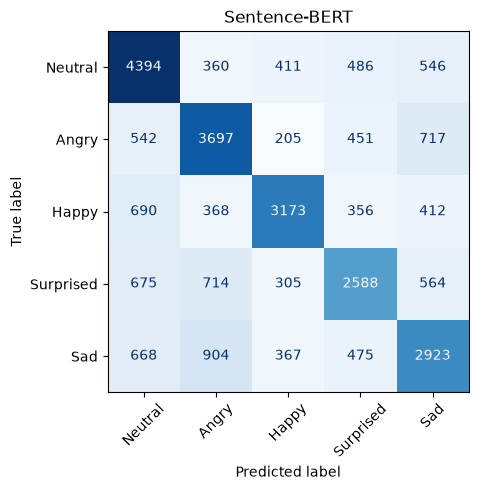

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

labels = ['Z', 'P', 'D', 'N', 'L']
names = {'Z': 'Neutral', 'P': 'Angry', 'D': 'Happy', 'N': 'Surprised', 'L': 'Sad'}
display_labels = [names[l] for l in labels]

def evaluate(model, X_test, y_test, title):
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, y_pred, average='macro', zero_division=0)

    print(f"{title}")
    print(f"Accuracy: {acc:.3f} | Precision (macro): {p:.3f} | "
          f"Recall (macro): {r:.3f} | F1 (macro): {f1:.3f}\n")
    print(classification_report(y_test, y_pred, labels=labels,
                                target_names=display_labels, digits=3,
                                zero_division=0))

    cm = confusion_matrix(y_test, y_pred, labels=labels)
    return {'model': title, 'accuracy': acc, 'precision': p,
            'recall': r, 'f1': f1, 'cm': cm}

def plot_cm(cm, title, filename=None):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=display_labels).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    if filename:
        plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

# Sentence-BERT + Logistic Regression

clf_sbert = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train classifier
clf_sbert.fit(X_train_sbert, y_train)

# Evaluate model
res_sbert = evaluate(
    clf_sbert,
    X_test_sbert,
    y_test,
    "Sentence-BERT"
)

# Plot confusion matrix
plot_cm(
    res_sbert['cm'],
    "Sentence-BERT",
    "cm_sbert.png"
)
